In [1]:
import os
import glob
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import librosa
import scipy.io.wavfile as wavfile
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="darkgrid", context="notebook")

# 'Tom' provides the deepest, longest cavity resonance for an IR
TARGET_STROKE = "flam_mid" 
data_dir = os.path.join("..", "data", "raw", TARGET_STROKE)
wav_files = glob.glob(os.path.join(data_dir, "*.wav"))

if not wav_files:
    print(f"No .wav files found for '{TARGET_STROKE}' in {data_dir}.")

y, sr = librosa.load(wav_files[0], sr=44100)
y, _ = librosa.effects.trim(y, top_db=30)

In [2]:
# Isolate the slap (first 10ms)
exciter_samples = int(0.01 * sr)
x_exciter = np.zeros_like(y)
x_exciter[:exciter_samples] = y[:exciter_samples]

# Apply a quick fade-out to the exciter to avoid sudden clicks in the math
fade_out = np.linspace(1, 0, exciter_samples)
x_exciter[:exciter_samples] *= fade_out

print(f"Full Audio Length (Y): {len(y)} samples")
print(f"Exciter Length (X): {exciter_samples} samples ({exciter_samples/sr*1000:.1f} ms)")

Full Audio Length (Y): 10752 samples
Exciter Length (X): 441 samples (10.0 ms)


In [3]:
# 1. Compute FFTs
Y_fft = np.fft.fft(y)
X_fft = np.fft.fft(x_exciter)

# 2. Deconvolution with Regularization (similar to Wiener deconvolution)
# H(f) = [ Y(f) * conj(X(f)) ] / [ |X(f)|^2 + epsilon ]
epsilon = 1e-3 * np.max(np.abs(X_fft)**2) # Regularization factor
H_fft = (Y_fft * np.conjugate(X_fft)) / (np.abs(X_fft)**2 + epsilon)

# 3. Inverse FFT to return to the time domain
h_ir = np.real(np.fft.ifft(H_fft))

# 4. Cleanup the IR
# The IR might have some pre-ringing noise at the very end due to circular convolution.
# We apply an exponential decay envelope to ensure it fades to absolute digital zero.
decay_envelope = np.exp(-np.linspace(0, 10, len(h_ir)))
h_ir = h_ir * decay_envelope

# Normalize the final Impulse Response
if np.max(np.abs(h_ir)) > 0:
    h_ir = h_ir / np.max(np.abs(h_ir))

# Save the IR to disk
out_dir = os.path.join("..", "data", "processed", "impulse_responses")
os.makedirs(out_dir, exist_ok=True)
ir_path = os.path.join(out_dir, f"{TARGET_STROKE}_cavity_IR.wav")
wavfile.write(ir_path, sr, h_ir.astype(np.float32))
print(f"Cavity Impulse Response saved to: {ir_path}")

Cavity Impulse Response saved to: ../data/processed/impulse_responses/flam_mid_cavity_IR.wav


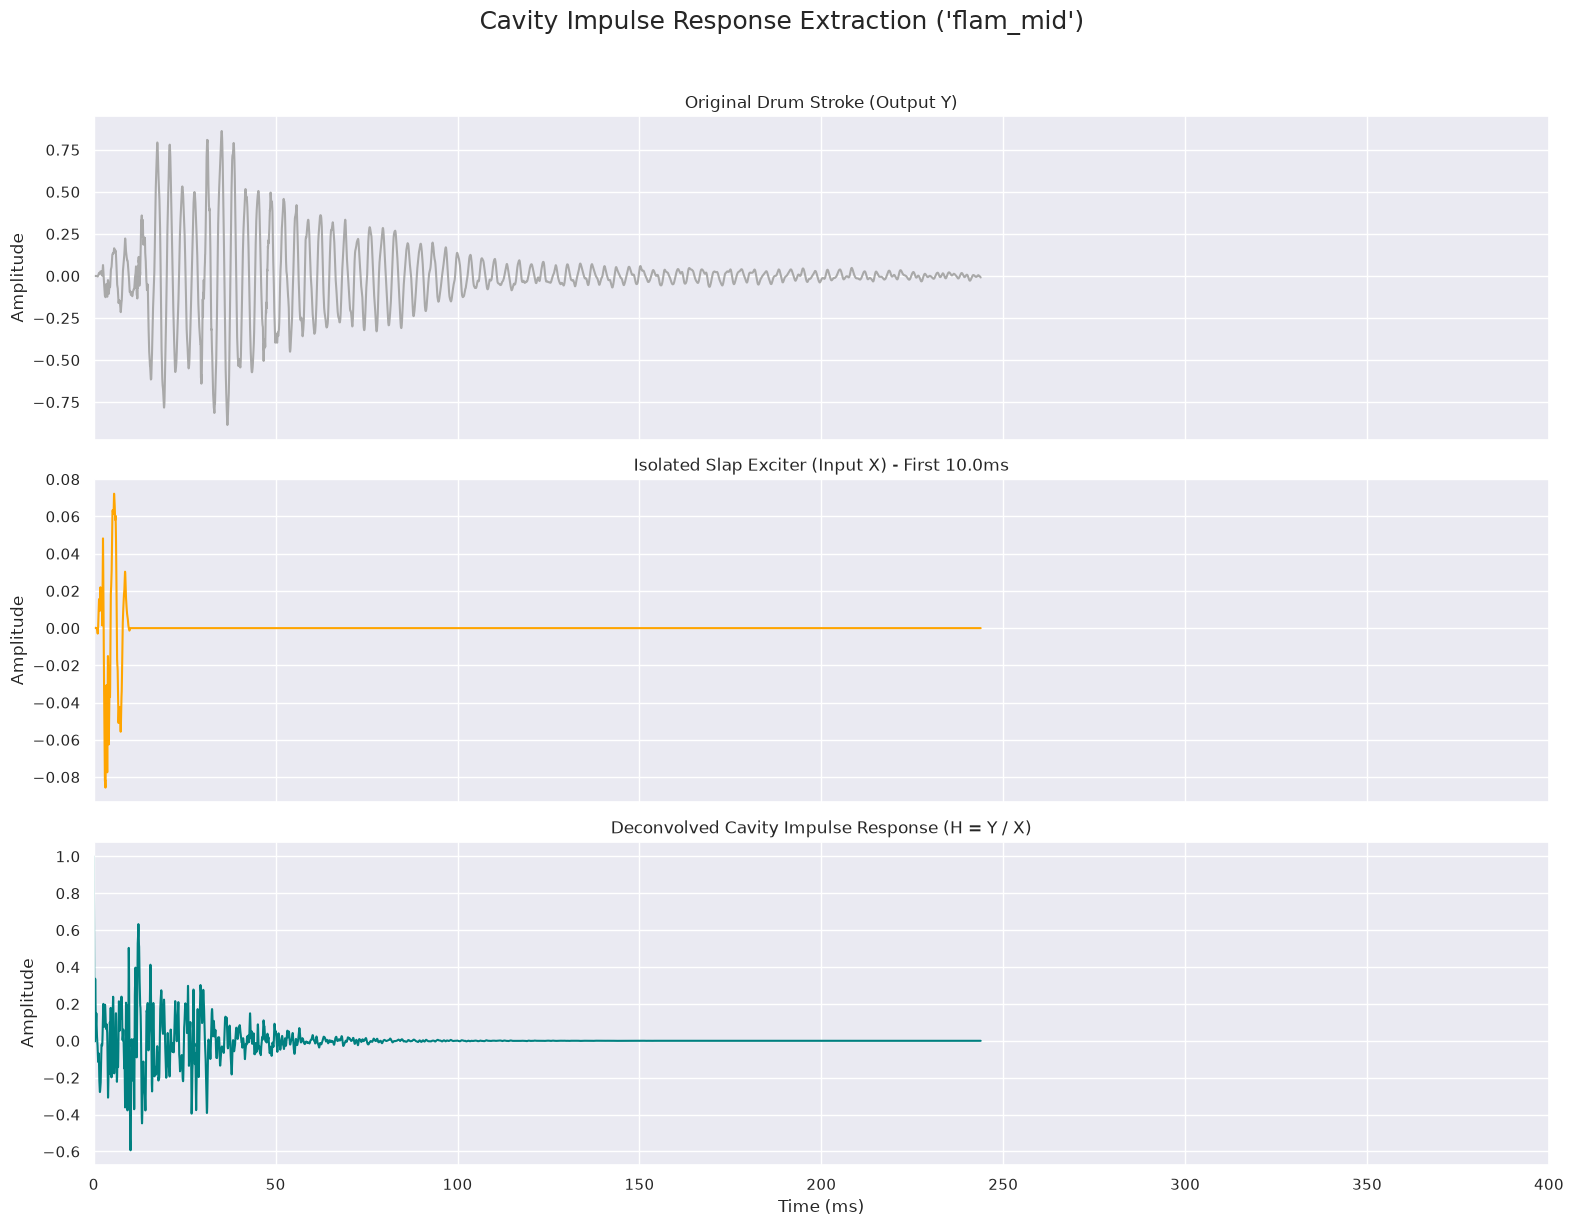

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(16, 12), sharex=True)
fig.suptitle(f"Cavity Impulse Response Extraction ('{TARGET_STROKE}')", fontsize=18, y=1.02)

time_axis = np.arange(len(y)) / sr * 1000  # ms

# 1. Full Stroke (Y)
axes[0].plot(time_axis, y, color='darkgray')
axes[0].set_title("Original Drum Stroke (Output Y)")
axes[0].set_ylabel("Amplitude")

# 2. Exciter (X)
axes[1].plot(time_axis, x_exciter, color='orange')
axes[1].set_title(f"Isolated Slap Exciter (Input X) - First {exciter_samples/sr*1000:.1f}ms")
axes[1].set_ylabel("Amplitude")

# 3. Extracted Impulse Response (H)
axes[2].plot(time_axis, h_ir, color='teal')
axes[2].set_title("Deconvolved Cavity Impulse Response (H = Y / X)")
axes[2].set_xlabel("Time (ms)")
axes[2].set_ylabel("Amplitude")

plt.xlim(0, 400) # Zoom into the relevant decay
plt.tight_layout()
plt.show()